# Etapa 2 — Modelo matemático de la subred Polanco

**MA2004B · Ecobici · septiembre 2026, 21 días hábiles**

Cada estación es una **cadena de Markov de nacimiento y muerte en tiempo continuo**:

- Estado $X(t)$ = bicis ancladas, de $0$ a $K$ (docks del GBFS).
- **Nacimiento:** llega alguien a dejar una bici, tasa $\mu(t)$. Si $X = K$ no hay dock → **arribo rechazado**.
- **Muerte:** alguien saca una bici, tasa $\lambda(t)$. Si $X = 0$ no hay bici → **retiro perdido**.
- $\lambda(t)$ y $\mu(t)$ son constantes por bloques de 15 min (Poisson no homogéneo).

```
        μ        μ        μ               μ
   0 ⇄ 1 ⇄ 2 ⇄ ... ⇄ K
        λ        λ        λ               λ
```

El notebook hace cuatro cosas, en este orden:
1. Detecta la **censura** (minutos con la estación vacía o llena, donde la demanda no se registra) y corrige las tasas.
2. **Prueba los supuestos** del modelo contra los datos.
3. Reconstruye con el **ID de la bici** lo que hoy hace el operador.
4. **Resuelve el modelo** (ecuaciones de Kolmogorov hacia adelante) y calcula las fallas esperadas.

Solo necesita las salidas de la Etapa 1: `viajes_limpios.csv(.gz)` y `estaciones.csv`. Corre en ~30 s.

## 0. Librerías y parámetros

Todo lo que se puede mover está aquí. Si quieren probar sensibilidad (otro umbral, bloques de 30 min, sin fusionar 211+212), cambien el valor y corran todo de nuevo.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.linalg import expm
import matplotlib.pyplot as plt
import os
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

In [2]:
# rutas (salidas de la Etapa 1)
LIMPIOS = "out/viajes_limpios.csv"   # también sirve el .csv sin comprimir
ESTACIONES = "out/estaciones.csv"
OUT = "out/modelo"
os.makedirs(OUT, exist_ok=True)

# ----------------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------------
SUBRED = ["211", "212", "208", "204", "210", "217", "207", "205", "201", "225"]
FUENTES, SUMIDEROS = SUBRED[:5], SUBRED[5:]
# 211 y 212 están en la misma esquina (Horacio entre Newton y Hegel, ~20 m): los usuarios las usan
# como una sola. Se modelan también como un nodo fusionado con K = K211 + K212.
FUSION = {"211+212": ["211", "212"]}
SUBRED_M = SUBRED + list(FUSION)
MIEMBROS = {**{s: [s] for s in SUBRED}, **FUSION}
T0, T1 = 5 * 60, 24 * 60 + 30     # día de servicio en minutos desde las 00:00: 05:00 a 00:30
B = 15                             # tamaño del bloque para lambda(t), mu(t), en minutos
NB = (T1 - T0) // B
UMBRAL_HUECO = 6.9                 # un hueco sin eventos con Lambda > 6.9 tiene prob. e^-6.9 = 0.1% bajo Poisson
ITER_CENSURA = 4                   # iteraciones estimar tasa -> detectar huecos -> reestimar
GRUPO_T1, GRUPO_T2 = 1.0, 2.0      # viaje en grupo: mismo origen y destino, salen a <1 min y llegan a <2 min
MIN_CELDA = 1.0                    # media mínima por celda para la prueba de dispersión
MAX_BICIS_DANADAS = 2              # hueco de retiros con <= 2 bicis quietas todo el tiempo = vacía de bicis útiles

## 1. Carga de datos y eventos

Cada viaje se vuelve dos eventos: un **retiro** en la estación de origen y un **arribo** en la de destino, con la hora en minutos desde las 00:00 del día de servicio (las 00:15 de la madrugada cuentan como 24:15 del día anterior, igual que en la limpieza).

También se marcan los **viajes en grupo**: mismo origen y destino, salen a menos de 1 min y llegan a menos de 2 min uno del otro. Sirven para checar si la gente llega de una en una (supuesto de Poisson).

In [3]:
c = pd.read_csv(LIMPIOS, dtype={"Ciclo_Estacion_Retiro": str, "Ciclo_EstacionArribo": str, "dia_atipico": str},
                parse_dates=["ts_retiro", "ts_arribo"])
est = pd.read_csv(ESTACIONES, dtype={"codigo": str}).set_index("codigo")
K = est["capacidad"].reindex(SUBRED).astype(int)
NOM = est["nombre"].reindex(SUBRED).str.replace(r"^CE-\d+\s+", "", regex=True)
for f, mm in FUSION.items():
    K[f] = int(K[mm].sum()); NOM[f] = " + ".join(NOM[m] for m in mm)
d0 = pd.to_datetime(c["fecha_servicio"])
c["tr"] = (c["ts_retiro"] - d0).dt.total_seconds() / 60     # minutos desde 00:00 del día de servicio
c["ta"] = (c["ts_arribo"] - d0).dt.total_seconds() / 60
DIAS = sorted(c["fecha_servicio"].unique())
ND = len(DIAS)

# eventos de la subred: un retiro o un arribo por viaje
ev = pd.concat([
    pd.DataFrame({"est": c.Ciclo_Estacion_Retiro, "otra": c.Ciclo_EstacionArribo, "dia": c.fecha_servicio,
                  "t": c.tr, "t_otra": c.ta, "tipo": "ret"}),
    pd.DataFrame({"est": c.Ciclo_EstacionArribo, "otra": c.Ciclo_Estacion_Retiro, "dia": c.fecha_servicio,
                  "t": c.ta, "t_otra": c.tr, "tipo": "arr"})], ignore_index=True)
ev = ev[ev.est.isin(SUBRED) & (ev.t >= T0) & (ev.t < T1)]
ev = pd.concat([ev] + [ev[ev.est.isin(mm)].assign(est=f) for f, mm in FUSION.items()], ignore_index=True)
ev = ev.sort_values(["est", "tipo", "dia", "otra", "t"])

# viajes en grupo (dos o más personas que salen y llegan juntas)
prev = ev.shift()
mismo = (ev.est.eq(prev.est) & ev.tipo.eq(prev.tipo) & ev.dia.eq(prev.dia) & ev.otra.eq(prev.otra)
         & (ev.t - prev.t <= GRUPO_T1) & ((ev.t_otra - prev.t_otra).abs() <= GRUPO_T2))
ev["grupo"] = (~mismo).cumsum()
ev = ev.sort_values(["est", "tipo", "dia", "t"]).reset_index(drop=True)
tam = ev[ev.est.isin(SUBRED)].groupby("grupo").size()
frac_grupo = tam[tam > 1].sum() / tam.sum()
evg = ev.drop_duplicates("grupo")      # un evento por grupo

print(f"{len(c):,} viajes limpios, {ND} días hábiles")
print(f"eventos en la subred: {(ev.est.isin(SUBRED)).sum():,}   viajes en grupo: {frac_grupo:.1%}")
display(pd.DataFrame({"K": K, "nombre": NOM}))

1,173,180 viajes limpios, 21 días hábiles
eventos en la subred: 48,592   viajes en grupo: 4.1%


,K,nombre
codigo,,
211,35,Isaac Newton-Horacio
212,35,Hegel-Horacio
208,25,Hesiodo-Lamartine
204,27,Temístocles-Homero
210,27,Eugenio Sue-Horacio
217,31,Euler-Horacio
207,23,Torquato Tasso-Homero
205,19,Taine-Homero
201,19,Lope de Vega-Av. Ejército Nacional


## 2. Funciones de apoyo

- `tasa()`: estima $\hat\lambda_b = \dfrac{\text{eventos en el bloque } b}{\text{minutos de exposición en } b}$. Es el estimador de máxima verosimilitud de Poisson cuando una parte del tiempo está censurada.
- `Lambda()`: tasa acumulada $\Lambda(t) = \int_{05:00}^{t} \lambda(s)\,ds$ (lineal por tramos).
- `huecos()`: un hueco sin eventos entre $t_1$ y $t_2$ tiene probabilidad $e^{-(\Lambda(t_2)-\Lambda(t_1))}$ bajo Poisson. Si $\Lambda(t_2)-\Lambda(t_1) > 6.9$, la probabilidad es menor a 0.1% y lo marcamos.
- `quitar_exposicion()`: resta esos minutos de la exposición del bloque.

In [4]:
def tiempos(df):
    return {d: g.t.values for d, g in df.groupby("dia")}


def tasa(tb, expo):
    """tasa por minuto en cada bloque = eventos / minutos de exposición (MLE de Poisson con censura)."""
    N = np.zeros(NB); E = np.zeros(NB)
    for d in DIAS:
        t = tb.get(d, np.array([]))
        np.add.at(N, ((t - T0) // B).astype(int), 1)
        E += expo[d]
    return N / np.maximum(E, 1e-9), N, E


def Lambda(rate):
    cum = np.concatenate([[0], np.cumsum(rate * B)])
    def L(t):
        t = np.clip(np.asarray(t, float), T0, T1 - 1e-9)
        b = ((t - T0) // B).astype(int)
        return cum[b] + rate[b] * (t - T0 - b * B)
    return L


def huecos(t, L, umbral):
    pts = np.concatenate([[T0], np.sort(t), [T1]])
    g = np.diff(L(pts))
    return [(pts[i], pts[i + 1], g[i]) for i in np.where(g > umbral)[0]], len(g)


def quitar_exposicion(expo, d, a, b):
    for k in range(int((a - T0) // B), int(min((b - T0) // B, NB - 1)) + 1):
        lo = T0 + k * B
        expo[d][k] -= max(0.0, min(b, lo + B) - max(a, lo))


def interseca(A, Bv):
    out = []
    for d, a, b in A:
        for d2, a2, b2 in Bv:
            if d == d2 and min(b, b2) > max(a, a2):
                out.append((d, max(a, a2), min(b, b2)))
    return out

## 3. Censura: detectar estaciones vacías o llenas

El CSV solo tiene viajes completados: si alguien llega y no hay bici, no queda registro. Para encontrar esos momentos:

1. Se estima $\lambda(t)$ con todos los minutos.
2. Se marcan los huecos sin retiros con probabilidad < 0.1%.
3. Se quitan esos minutos de la exposición y se vuelve a estimar. Se repite 4 veces.

Lo mismo con arribos para detectar estaciones **llenas**.

In [5]:
# ----------------------------------------------------------------------------
# 1-2. Censura y tasas corregidas
# ----------------------------------------------------------------------------
TB = {(s, tp): tiempos(ev[(ev.est == s) & (ev.tipo == tp)]) for s in SUBRED_M for tp in ("ret", "arr")}
cruda, corr, marcados, n_huecos = {}, {}, {}, {}
for key, tb in TB.items():
    expo = {d: np.full(NB, float(B)) for d in DIAS}
    cruda[key] = tasa(tb, expo)[0]
    for _ in range(ITER_CENSURA):
        r = tasa(tb, expo)[0]
        L = Lambda(r)
        expo = {d: np.full(NB, float(B)) for d in DIAS}
        fl, ng = [], 0
        for d in DIAS:
            f, k = huecos(tb.get(d, np.array([])), L, UMBRAL_HUECO)
            ng += k
            fl += [(d, a, b) for a, b, _ in f]
            for a, b, _ in f:
                quitar_exposicion(expo, d, a, b)
    marcados[key], n_huecos[key] = fl, ng

print("huecos marcados (antes de verificar):")
display(pd.DataFrame({k: len(v) for k, v in marcados.items()}, index=["huecos"]).T.unstack())

huecos marcados (antes de verificar):


huecos    
           arr ret
201          7  10
204          3  28
205          5  15
207          5  10
208         17  40
210          4  24
211         14  42
211+212     14  47
212          4  22
217         24  13
225          3   9

## 4. Rastreo por ID de bici

Ordenando los viajes de cada bici:

- Si una bici **llega a A y su siguiente viaje sale de A**, estuvo anclada en A todo ese tiempo (bici "quieta"). Sumándolas sale un **mínimo seguro del inventario** minuto a minuto (`LB`).
- Si **llega a A y su siguiente viaje sale de B ≠ A**, nadie la pedaleó: **la movió el operador**.

No se usan cadenas con un fin de semana o festivo de por medio, porque esos viajes no están en los datos limpios.

Si las bicis confirmadas ya son ≥ K, la estación está **llena con certeza**.

In [6]:
# ----------------------------------------------------------------------------
# Rastreo por ID de bici: cadenas "llega a A en t1 -> su siguiente viaje sale de B en t2"
# ----------------------------------------------------------------------------
cb = c.sort_values(["Bici", "ts_retiro"]).reset_index(drop=True)
sig = cb.groupby("Bici").shift(-1)
ch = pd.DataFrame({"A": cb.Ciclo_EstacionArribo, "t1": cb.ts_arribo, "d1": pd.to_datetime(cb.fecha_servicio),
                   "B": sig.Ciclo_Estacion_Retiro, "t2": sig.ts_retiro, "d2": pd.to_datetime(sig.fecha_servicio)}).dropna(subset=["B"])
ch = ch[((ch.d2 - ch.d1).dt.days <= 1) & (ch.t2 >= ch.t1)]   # sin fin de semana ni festivo de por medio
quieta = ch[ch.A == ch.B]                                      # bici que se quedó anclada en A de t1 a t2 (confirmada)

# cota inferior del inventario, minuto a minuto: bicis confirmadas en la estación
grid = pd.date_range(pd.Timestamp(DIAS[0]), pd.Timestamp(DIAS[-1]) + pd.Timedelta("1D"), freq="1min")
gmin = np.asarray(grid.hour * 60 + grid.minute)
madrugada = gmin < 30                                   # 00:00-00:30 pertenecen al día de servicio anterior
gdia = np.asarray((grid - pd.to_timedelta(madrugada.astype(int), unit="D")).strftime("%Y-%m-%d"))
gmin = np.where(madrugada, gmin + 1440, gmin)
en_servicio = np.isin(gdia, DIAS) & (gmin >= T0) & (gmin < T1)
LB, LLENA_CONF = {}, {}
for s in SUBRED_M:
    q = quieta[quieta.A.isin(MIEMBROS[s]) & quieta.B.isin(MIEMBROS[s])]
    a = np.searchsorted(grid.values, q.t1.values.astype(grid.values.dtype))
    b = np.searchsorted(grid.values, q.t2.values.astype(grid.values.dtype))
    o = np.zeros(len(grid) + 1, int); np.add.at(o, a, 1); np.add.at(o, b, -1)
    LB[s] = np.cumsum(o)[:-1]
    # tramos en que la estación está llena con certeza (bicis confirmadas >= docks)
    full = (LB[s] >= K[s]) & en_servicio
    cambios = np.flatnonzero(np.diff(np.concatenate([[0], full.astype(int), [0]])))
    LLENA_CONF[s] = [(gdia[i], gmin[i], gmin[j - 1] + 1) for i, j in zip(cambios[::2], cambios[1::2])]


def union(iv):
    """une intervalos (dia, a, b) que se traslapan."""
    out = []
    for d, a, b in sorted(iv):
        if out and out[-1][0] == d and a <= out[-1][2]:
            out[-1] = (d, out[-1][1], max(out[-1][2], b))
        else:
            out.append((d, a, b))
    return out


def bicis_todo_el_hueco(s, d, a, b):
    """bicis confirmadas en s durante TODO el intervalo [a, b] (minutos del día de servicio d)."""
    ta = pd.Timestamp(d) + pd.Timedelta(minutes=float(a)); tb = pd.Timestamp(d) + pd.Timedelta(minutes=float(b))
    q = quieta[quieta.A.isin(MIEMBROS[s]) & quieta.B.isin(MIEMBROS[s]) & (quieta.t1 <= ta) & (quieta.t2 >= tb)]
    return len(q)

print(f"cadenas de bici útiles: {len(ch):,}   cambian de estación sin viaje (operador): {(ch.A != ch.B).mean():.1%}")
print("minutos por día con la estación llena confirmada:", {s: round(float(((LB[s] >= K[s]) & en_servicio).sum() / ND), 1) for s in SUBRED})

cadenas de bici útiles: 1,137,059   cambian de estación sin viaje (operador): 9.2%
minutos por día con la estación llena confirmada: {'211': 0.0, '212': 0.0, '208': 0.9, '204': 0.0, '210': 0.0, '217': 7.1, '207': 0.0, '205': 25.5, '201': 10.6, '225': 52.1}


## 5. Clasificar cada hueco y verificarlo

- Si faltan **retiros y arribos al mismo tiempo**, la estación estaba **fuera de servicio** (no es falla, pero tampoco cuenta como exposición).
- Un hueco de retiros con **3 o más bicis quietas todo el tiempo**, o donde llegaron 3+ bicis y nadie las tomó, **no es estación vacía** → *hueco no explicado*, no se corrige.
- Con **1 o 2 bicis quietas** en plena demanda, lo más probable es que estén dañadas → *vacía (solo bicis sin usar)*.
- Para llenas, lo mismo al revés: si salieron 3+ bicis (se liberaron docks) y nadie llegó, no estaba llena.

In [7]:
# si faltan retiros y arribos al mismo tiempo, la estación estaba fuera de servicio, no vacía ni llena
episodios = []
for s in SUBRED_M:
    fs = interseca(marcados[(s, "ret")], marcados[(s, "arr")])
    for d, a, b in fs:
        episodios.append((s, d, a, b, "fuera de servicio"))
    for tp, lab in (("ret", "vacía (faltan retiros)"), ("arr", "llena (faltan arribos)")):
        for d, a, b in marcados[(s, tp)]:
            # parte del hueco que no es fuera de servicio
            resto = [(a, b)]
            for d2, a2, b2 in fs:
                if d2 != d:
                    continue
                nuevo = []
                for x, y in resto:
                    if b2 <= x or a2 >= y:
                        nuevo.append((x, y))
                    else:
                        if a2 > x: nuevo.append((x, a2))
                        if b2 < y: nuevo.append((b2, y))
                resto = nuevo
            for x, y in resto:
                if y - x > 0.5:
                    episodios.append((s, d, x, y, lab))
EP = pd.DataFrame(episodios, columns=["codigo", "dia", "inicio_min", "fin_min", "tipo"])
EP["bicis_quietas"] = [bicis_todo_el_hueco(s, d, a, b) for s, d, a, b in zip(EP.codigo, EP.dia, EP.inicio_min, EP.fin_min)]
# Verificación con el ID de la bici. Un hueco de retiros con 3 o más bicis ancladas todo el tiempo no
# es una estación vacía: se descarta como censura (cuenta como exposición normal). Con 1-2 bicis
# quietas en plena demanda lo más probable es que estén dañadas: se acepta como vacía "de bicis útiles".
# Segunda verificación, simétrica: si en un hueco de retiros llegan 3+ bicis y nadie las toma, había
# bicis; si en un hueco de arribos salen 3+ bicis (se liberan docks) y nadie llega, había docks.
def eventos_dentro(s, tp, d, a, b):
    t = TB[(s, tp)].get(d, np.array([]))
    return int(((t > a) & (t < b)).sum())


EP["eventos_contrarios"] = [eventos_dentro(s, "arr" if tp.startswith("vacía") else "ret", d, a, b)
                            for s, d, a, b, tp in zip(EP.codigo, EP.dia, EP.inicio_min, EP.fin_min, EP.tipo)]
vac = EP.tipo == "vacía (faltan retiros)"
lle = EP.tipo == "llena (faltan arribos)"
EP.loc[vac & EP.bicis_quietas.between(1, MAX_BICIS_DANADAS), "tipo"] = "vacía (solo bicis sin usar)"
EP.loc[vac & ((EP.bicis_quietas > MAX_BICIS_DANADAS) | (EP.eventos_contrarios > MAX_BICIS_DANADAS)), "tipo"] = "hueco no explicado (no se corrige)"
EP.loc[lle & (EP.eventos_contrarios > MAX_BICIS_DANADAS), "tipo"] = "hueco no explicado (no se corrige)"
EP["censura"] = EP.tipo != "hueco no explicado (no se corrige)"


def max_conf_sobre_K(s, d, a, b):
    m = (gdia == d) & (gmin >= a) & (gmin < b)
    return LB[s][m].max() / K[s] if m.any() else np.nan


EP["max_bicis_confirmadas/K"] = [round(max_conf_sobre_K(s, d, a, b), 3) for s, d, a, b in zip(EP.codigo, EP.dia, EP.inicio_min, EP.fin_min)]
EP["inicio"] = EP.inicio_min.map(lambda m: f"{int(m // 60) % 24:02d}:{int(m % 60):02d}")
EP["fin"] = EP.fin_min.map(lambda m: f"{int(m // 60) % 24:02d}:{int(m % 60):02d}")
EP["duracion_min"] = (EP.fin_min - EP.inicio_min).round(1)
EP.to_csv(f"{OUT}/episodios_censura.csv", index=False)
ES_VACIA = EP.tipo.str.startswith("vacía")
ES_LLENA = EP.tipo.str.startswith("llena")
ES_FUERA = EP.tipo == "fuera de servicio"

resumen_ep = EP[EP.codigo.isin(SUBRED)].groupby("tipo").agg(episodios=("duracion_min", "size"), min_por_dia=("duracion_min", lambda x: round(x.sum() / ND, 1)))
display(resumen_ep)
print("ejemplos:")
display(EP[EP.codigo.isin(SUBRED)].sort_values("duracion_min", ascending=False)[["codigo", "dia", "inicio", "fin", "duracion_min", "tipo", "bicis_quietas", "eventos_contrarios"]].head(8))

,episodios,min_por_dia
tipo,,
fuera de servicio,20,61.1
hueco no explicado (no se corrige),109,304.2
llena (faltan arribos),53,103.5
vacía (faltan retiros),88,200.5
vacía (solo bicis sin usar),45,92.6


ejemplos:


,codigo,dia,inicio,fin,duracion_min,tipo,bicis_quietas,eventos_contrarios
177,210,2026-09-01,18:48,00:30,341.7,hueco no explicado (no se corrige),9,2
191,210,2026-09-23,19:29,00:30,300.4,vacía (faltan retiros),0,2
4,211,2026-09-30,05:00,09:59,299.3,fuera de servicio,1,0
222,217,2026-09-01,19:44,00:30,285.2,hueco no explicado (no se corrige),0,8
0,211,2026-09-03,05:14,08:53,218.6,fuera de servicio,7,0
197,210,2026-09-28,19:06,22:25,199.4,vacía (faltan retiros),0,1
196,210,2026-09-25,18:47,21:42,174.8,vacía (faltan retiros),0,0
313,225,2026-09-01,21:36,00:30,173.4,hueco no explicado (no se corrige),1,4


## 6. Tasas corregidas

Ahora sí: $\hat\lambda_b$ y $\hat\mu_b$ con la exposición sin los minutos censurados que pasaron la verificación (más los minutos de llena confirmada para arribos).

La **demanda que no se ve** es $\int \hat\lambda(t)\,dt$ sobre los episodios de vacía (o $\hat\mu$ sobre los de llena). Es una **cota inferior**: los huecos cortos no se detectan.

In [8]:
# tasas corregidas: los minutos censurados aceptados no cuentan como exposición
CENS = {}
for s in SUBRED_M:
    for tp, m in (("ret", ES_VACIA), ("arr", ES_LLENA)):
        e = EP[(EP.codigo == s) & (m | ES_FUERA)]
        iv = list(zip(e.dia, e.inicio_min, e.fin_min))
        if tp == "arr":            # además, los minutos en que la estación está llena confirmada
            iv += LLENA_CONF[s]
        CENS[(s, tp)] = union(iv)
        expo = {d: np.full(NB, float(B)) for d in DIAS}
        for d, a, b in CENS[(s, tp)]:
            quitar_exposicion(expo, d, a, b)
        corr[(s, tp)] = tasa(TB[(s, tp)], expo)[0]

# demanda que no se ve: integral de la tasa corregida sobre los episodios de vacía / llena
perdidos = {}
for s in SUBRED_M:
    for tp, m in (("ret", ES_VACIA), ("arr", ES_LLENA)):
        L = Lambda(corr[(s, tp)])
        e = EP[(EP.codigo == s) & m]
        iv = list(zip(e.dia, e.inicio_min, e.fin_min)) + (LLENA_CONF[s] if tp == "arr" else [])
        perdidos[(s, tp)] = float(sum(L(b) - L(a) for _, a, b in union(iv))) / ND

tas = []
for s in SUBRED_M:
    for tp in ("ret", "arr"):
        for k in range(NB):
            tas.append((s, "lambda" if tp == "ret" else "mu", T0 + k * B, cruda[(s, tp)][k] * 60, corr[(s, tp)][k] * 60))
TAS = pd.DataFrame(tas, columns=["codigo", "tasa", "min_inicio", "cruda_por_hora", "corregida_por_hora"])
TAS["hora"] = TAS.min_inicio.map(lambda m: f"{int(m // 60) % 24:02d}:{int(m % 60):02d}")
TAS.round(3).to_csv(f"{OUT}/tasas_15min.csv", index=False)

comp = pd.DataFrame({s: {"λ cruda/día": cruda[(s, "ret")].sum() * B, "λ corregida/día": corr[(s, "ret")].sum() * B, "retiros no vistos/día": perdidos[(s, "ret")],
                         "μ cruda/día": cruda[(s, "arr")].sum() * B, "μ corregida/día": corr[(s, "arr")].sum() * B, "arribos no vistos/día": perdidos[(s, "arr")]} for s in SUBRED_M}).T.round(1)
display(comp)
print("fuentes:", comp.loc[FUENTES].sum().round(0).to_dict())
print("sumideros:", comp.loc[SUMIDEROS].sum().round(0).to_dict())

,λ cruda/día,λ corregida/día,retiros no vistos/día,μ cruda/día,μ corregida/día,arribos no vistos/día
211,146.3,169.2,14.5,102.1,106.1,1.6
212,128.0,132.0,4.0,108.9,110.2,1.3
208,296.4,309.3,11.0,269.4,274.4,2.7
204,93.5,103.4,9.9,63.8,65.3,1.5
210,94.1,101.1,7.0,56.9,56.9,0.0
217,145.9,149.5,2.1,170.7,181.4,9.9
207,79.0,80.9,1.9,87.5,90.1,2.7
205,87.3,91.3,2.9,89.7,94.0,3.7
201,69.6,73.9,4.2,66.8,70.1,3.3
225,78.6,81.0,1.6,79.4,85.0,5.2


fuentes: {'λ cruda/día': 758.0, 'λ corregida/día': 815.0, 'retiros no vistos/día': 46.0, 'μ cruda/día': 601.0, 'μ corregida/día': 613.0, 'arribos no vistos/día': 7.0}
sumideros: {'λ cruda/día': 460.0, 'λ corregida/día': 477.0, 'retiros no vistos/día': 13.0, 'μ cruda/día': 494.0, 'μ corregida/día': 521.0, 'arribos no vistos/día': 25.0}


## 7. Pruebas de supuestos

### 7a. ¿Los conteos son Poisson?
En un Poisson, varianza = media. Para cada estación y cada bloque de 15 min se calcula el índice de dispersión de los conteos entre los 21 días y una prueba $\chi^2$.

In [9]:
P = []

# (a) Poisson: índice de dispersión de los conteos por bloque de 15 min entre los 21 días
def dispersion(df):
    df = df.assign(b=((df.t - T0) // B).astype(int))
    cnt = df.groupby(["est", "tipo", "b", "dia"]).size().unstack(fill_value=0).reindex(columns=DIAS, fill_value=0)
    m = cnt.mean(axis=1)
    X2 = (cnt.sub(m, axis=0) ** 2).sum(axis=1) / m
    r = pd.DataFrame({"m": m, "disp": cnt.var(axis=1) / m, "p": stats.chi2.sf(X2, ND - 1)})
    return r[r.m >= MIN_CELDA]

for lab, df in (("viajes", ev), ("grupos", evg)):
    r = dispersion(df)
    for (s, tp), g in r.groupby(level=[0, 1]):
        P.append(dict(prueba=f"dispersion_15min_{lab}", codigo=s, tipo=tp, n=len(g),
                      estadistico=round(g.disp.median(), 3), frac_rechazo_5pct=round((g.p < .05).mean(), 3)))

PT_tmp = pd.DataFrame(P)
display(PT_tmp[PT_tmp.codigo.isin(SUBRED)].groupby(["prueba", "tipo"])[["estadistico", "frac_rechazo_5pct"]].median().round(2))

estadistico  frac_rechazo_5pct
prueba                  tipo                                
dispersion_15min_grupos arr          1.00               0.14
                        ret          1.21               0.32
dispersion_15min_viajes arr          1.05               0.17
                        ret          1.24               0.33

### 7b. ¿Los tiempos entre eventos son exponenciales?
**Reescalamiento del tiempo:** si los eventos son Poisson con tasa $\lambda(t)$, los huecos $z_k = \Lambda(t_k) - \Lambda(t_{k-1})$ son $\text{Exp}(1)$. Se prueba con K-S, con la tasa cruda y con la corregida (quitando los huecos censurados).

Ojo: con miles de huecos el p-valor siempre sale chico. Lo que importa es **D** (distancia máxima entre las dos distribuciones acumuladas).

In [10]:
# (b) exponencialidad por reescalamiento del tiempo: si es Poisson con tasa lambda(t),
#     los huecos z = Lambda(t_k) - Lambda(t_{k-1}) son Exp(1). Prueba K-S.
Z = {}
for key in TB:
    s, tp = key
    tbg = tiempos(evg[(evg.est == s) & (evg.tipo == tp)])
    for lab, rate, quitar in (("cruda", cruda[key], False), ("corregida", corr[key], True)):
        L = Lambda(rate)
        zs = []
        for d, t in tbg.items():
            t = np.sort(t)
            z = np.diff(L(t))
            if quitar:  # se excluyen los huecos que caen dentro de un episodio censurado aceptado
                mid = (t[1:] + t[:-1]) / 2
                fuera = np.ones(len(z), bool)
                for d2, a, b in CENS[key]:
                    if d2 == d:
                        fuera &= ~((mid > a) & (mid < b))
                z = z[fuera]
            zs.append(z)
        zs = np.concatenate(zs)
        Z[(s, tp, lab)] = zs
        ks = stats.kstest(zs, "expon")
        P.append(dict(prueba=f"ks_exponencial_{lab}", codigo=s, tipo=tp, n=len(zs),
                      estadistico=round(ks.statistic, 4), p_valor=round(ks.pvalue, 4)))

PT_tmp = pd.DataFrame(P)
display(PT_tmp[PT_tmp.prueba.str.startswith("ks")].pivot_table(index=["codigo"], columns=["tipo", "prueba"], values="estadistico").round(3))

tipo                         arr                                           ret                     
prueba  ks_exponencial_corregida ks_exponencial_cruda ks_exponencial_corregida ks_exponencial_cruda
codigo                                                                                             
201                        0.012                0.023                    0.022                0.041
204                        0.028                0.024                    0.053                0.078
205                        0.023                0.014                    0.025                0.033
207                        0.027                0.028                    0.046                0.052
208                        0.008                0.006                    0.039                0.047
210                        0.017                0.017                    0.039                0.054
211                        0.047                0.052                    0.040                0.074
211+212                    0.022                0.024                    0.033                0.041
212                        0.021                0.023                    0.058                0.066
217                        0.020                0.028                    0.027                0.030
225                        0.024                0.030                    0.018                0.022

### 7c. ¿Basta un bloque de una hora?
$\chi^2$ de homogeneidad entre los 4 cuartos de cada hora. Si la tasa fuera constante en la hora, se rechazaría ~5% de las veces.

In [11]:
# (c) granularidad: ¿los cuatro cuartos de cada hora tienen la misma tasa?
g = ev.assign(h=(ev.t // 60).astype(int), q=((ev.t % 60) // 15).astype(int)) \
      .groupby(["est", "tipo", "h", "q"]).size().unstack(fill_value=0)
g = g[g.sum(axis=1) >= 40]
pv = g.apply(lambda r: stats.chisquare(r.values).pvalue, axis=1)
for (s, tp), x in pv.groupby(level=[0, 1]):
    P.append(dict(prueba="cuartos_de_hora_homogeneos", codigo=s, tipo=tp, n=len(x), frac_rechazo_5pct=round((x < .05).mean(), 3)))

print(f"horas donde los cuartos NO son homogéneos: {(pv < .05).mean():.0%}  (esperado 5%)")
print("por hora:", (pv < .05).groupby(level=2).mean().round(2).to_dict())

horas donde los cuartos NO son homogéneos: 43%  (esperado 5%)
por hora: {5: 0.75, 6: 0.86, 7: 0.73, 8: 0.45, 9: 0.64, 10: 0.14, 11: 0.05, 12: 0.27, 13: 0.36, 14: 0.23, 15: 0.36, 16: 0.36, 17: 0.45, 18: 0.67, 19: 0.5, 20: 0.53, 21: 0.31, 22: 0.5, 23: 0.8, 24: 1.0}


### 7d. Día de la semana y variación entre días
Kruskal-Wallis de los viajes diarios por día de la semana. Además, el factor diario $\theta_d$: si $\text{Var}(N) = m + \sigma^2 m^2$ (Poisson mixta), $\sigma$ mide cuánto cambia el volumen de un día a otro.

In [12]:
# (d) día de la semana (Kruskal-Wallis sobre viajes diarios de la subred)
diario = ev[ev.est.isin(SUBRED)].groupby("dia").size().reindex(DIAS)
dow = pd.to_datetime(pd.Series(DIAS)).dt.dayofweek.values
kw = stats.kruskal(*[diario.values[dow == k] for k in range(5)])
P.append(dict(prueba="kruskal_dia_semana", codigo="subred", tipo="ambos", n=ND, estadistico=round(kw.statistic, 3), p_valor=round(kw.pvalue, 4)))
m_d, v_d = diario.mean(), diario.var()
sigma_theta = np.sqrt(max(v_d - m_d, 0) / m_d ** 2)   # Var(N) = m + sigma^2 m^2 (Poisson mixta)
P.append(dict(prueba="factor_diario_sd", codigo="subred", tipo="ambos", n=ND, estadistico=round(sigma_theta, 4)))
rel = ev[ev.est.isin(SUBRED)].groupby(["est", "tipo", "dia"]).size().unstack(fill_value=0)
rel = rel.div(rel.mean(axis=1), axis=0)
C = np.corrcoef(rel.values)
P.append(dict(prueba="corr_media_series_diarias", codigo="subred", tipo="ambos", n=len(rel),
              estadistico=round(C[np.triu_indices_from(C, 1)].mean(), 3)))

print(f"Kruskal-Wallis p = {kw.pvalue:.2f}   factor diario sd = {sigma_theta:.3f}   corr media entre estaciones = {C[np.triu_indices_from(C, 1)].mean():.2f}")
display((diario / diario.mean()).round(2).to_frame("volumen relativo").T)

Kruskal-Wallis p = 0.47   factor diario sd = 0.075   corr media entre estaciones = 0.28


dia,2026-09-01,2026-09-02,2026-09-03,2026-09-04,2026-09-07,2026-09-08,2026-09-09,2026-09-10,2026-09-11,2026-09-14,2026-09-15,2026-09-17,2026-09-18,2026-09-21,2026-09-22,2026-09-23,2026-09-24,2026-09-25,2026-09-28,2026-09-29,2026-09-30
volumen relativo,0.98,1.02,1.0,1.04,0.87,1.09,1.12,1.09,0.95,1.01,0.88,0.98,0.95,1.0,1.03,1.13,1.05,0.88,1.01,1.01,0.88


### 7e. ¿Hay censura? Huecos improbables observados contra esperados
Con umbral de 0.1%, por puro azar se esperan $n_{\text{huecos}} \cdot e^{-6.9}$. Si salen muchos más, hay censura.

In [13]:
# (e) censura: ¿hay más huecos improbables de los que Poisson permite?
for key in TB:
    s, tp = key
    esperados = n_huecos[key] * np.exp(-UMBRAL_HUECO)
    obs = len(marcados[key])
    P.append(dict(prueba="huecos_improbables_obs_vs_esp", codigo=s, tipo=tp, n=n_huecos[key],
                  estadistico=obs, esperado=round(esperados, 2), p_valor=round(stats.poisson.sf(obs - 1, esperados), 6)))

h = pd.DataFrame(P); h = h[(h.prueba == "huecos_improbables_obs_vs_esp") & h.codigo.isin(SUBRED)].copy()
h["rol"] = np.where(h.codigo.isin(FUENTES), "se vacía (fuente)", "se llena (sumidero)")
display(h.groupby(["rol", "tipo"])[["estadistico", "esperado"]].sum().rename(columns={"estadistico": "observados"}).round(1))

observados  esperado
rol                 tipo                      
se llena (sumidero) arr         44.0      10.6
                    ret         57.0       9.8
se vacía (fuente)   arr         42.0      12.8
                    ret        156.0      16.2

### 7f. ¿Las estaciones son independientes?
Si casi todos los viajes entran o salen de fuera de la subred, se pueden modelar por separado.

In [14]:
# (f) independencia: fracción de viajes internos (acoplamiento entre estaciones)
toca = c.Ciclo_Estacion_Retiro.isin(SUBRED) | c.Ciclo_EstacionArribo.isin(SUBRED)
interno = c.Ciclo_Estacion_Retiro.isin(SUBRED) & c.Ciclo_EstacionArribo.isin(SUBRED)
P.append(dict(prueba="frac_viajes_internos", codigo="subred", tipo="ambos", n=int(toca.sum()), estadistico=round(interno.sum() / toca.sum(), 4)))
P.append(dict(prueba="frac_viajes_en_grupo", codigo="subred", tipo="ambos", n=len(ev), estadistico=round(frac_grupo, 4)))

PT = pd.DataFrame(P)
PT.to_csv(f"{OUT}/pruebas_supuestos.csv", index=False)
print(f"viajes internos: {interno.sum() / toca.sum():.1%}   viajes en grupo: {frac_grupo:.1%}")

viajes internos: 7.3%   viajes en grupo: 4.1%


### 7g. ¿211 y 212 son la misma estación?
Están en la misma esquina (~20 m). Si la gente las usa como una sola, los retiros juntos deberían ajustar mejor a Poisson que por separado (cuando una se vacía, la demanda se pasa a la otra).

In [15]:
display(PT[PT.prueba.str.startswith("ks") & PT.codigo.isin(["211", "212", "211+212"]) & (PT.tipo == "ret")][["codigo", "prueba", "estadistico"]])

,codigo,prueba,estadistico
44,211,ks_exponencial_cruda,0.0735
45,211,ks_exponencial_corregida,0.0397
48,212,ks_exponencial_cruda,0.0663
49,212,ks_exponencial_corregida,0.0580
84,211+212,ks_exponencial_cruda,0.0409
85,211+212,ks_exponencial_corregida,0.0333


## 8. Lo que hoy hace el operador

Bicis que cambian de estación sin que haya un viaje = las movió el operador. Así sale la **política actual**, contra la que se compara en la Etapa 3.

In [16]:
mov = ch[ch.A != ch.B]      # la bici cambió de estación sin que haya un viaje: la movió el operador
REP = pd.DataFrame({
    "metidas_dia": {s: (mov.B.isin(MIEMBROS[s]) & ~mov.A.isin(MIEMBROS[s])).sum() / ND for s in SUBRED_M},
    "sacadas_dia": {s: (mov.A.isin(MIEMBROS[s]) & ~mov.B.isin(MIEMBROS[s])).sum() / ND for s in SUBRED_M}}).reindex(SUBRED_M)
REP["neto_dia"] = REP.metidas_dia - REP.sacadas_dia
# hora de las que se meten el mismo día con ventana corta (cota superior = hora del siguiente retiro)
x = mov[mov.B.isin(SUBRED) & (mov.d1 == mov.d2) & ((mov.t2 - mov.t1).dt.total_seconds() <= 2 * 3600)]
hora_meten = x.t2.dt.hour.value_counts().sort_index()
REP.index.name = "codigo"
REP.round(2).to_csv(f"{OUT}/reposiciones.csv")
frac_mov = (ch.A != ch.B).mean()

conf_llena = {s: ((LB[s] >= K[s]) & en_servicio).sum() / ND for s in SUBRED_M}
# inventario confirmado a las 05:00 (bicis que pasaron la noche y salieron de la misma estación)
x05 = {s: np.median(LB[s][(gmin == T0) & en_servicio]) for s in SUBRED_M}

display(REP.round(1))
print("neto a fuentes:", round(REP.loc[FUENTES, "neto_dia"].sum(), 1), "  neto a sumideros:", round(REP.loc[SUMIDEROS, "neto_dia"].sum(), 1))
print("hora (cota superior) en que mete bicis, total del mes:", hora_meten.to_dict())

,metidas_dia,sacadas_dia,neto_dia
codigo,,,
211,58.6,23.6,35.0
212,37.0,25.7,11.3
208,72.2,48.4,23.9
204,31.8,8.6,23.2
210,37.5,7.0,30.6
217,14.7,38.7,-24.0
207,9.8,18.2,-8.4
205,9.0,11.2,-2.2
201,15.5,12.5,3.0


neto a fuentes: 124.0   neto a sumideros: -33.0
hora (cota superior) en que mete bicis, total del mes: {7: 237, 8: 817, 9: 597, 10: 240, 11: 62, 12: 16, 13: 15, 14: 6, 15: 6, 16: 29, 17: 121, 18: 115, 19: 39, 20: 44, 21: 143, 22: 13, 23: 1}


In [17]:
col_f, col_s = "#d95f02", "#1b7837"
rol = {s: col_f if s in FUENTES else col_s for s in SUBRED}
xh = (np.arange(NB) * B + T0) / 60
ticks = [5, 8, 11, 14, 17, 20, 23]

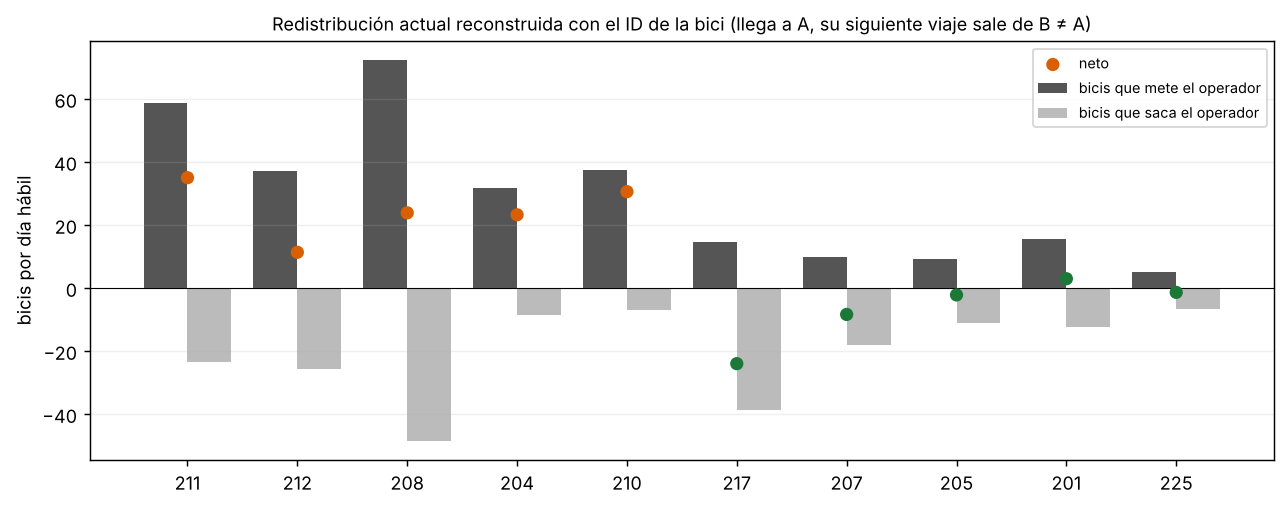

In [18]:
# 6. operador hoy
fig, ax = plt.subplots(figsize=(10, 4), dpi=130)
xx = np.arange(len(SUBRED))
ax.bar(xx - .2, REP.loc[SUBRED, "metidas_dia"], width=.4, color="#555555", label="bicis que mete el operador")
ax.bar(xx + .2, -REP.loc[SUBRED, "sacadas_dia"], width=.4, color="#bbbbbb", label="bicis que saca el operador")
ax.scatter(xx, REP.loc[SUBRED, "neto_dia"], color=[rol[s] for s in SUBRED], zorder=3, s=40, label="neto")
ax.axhline(0, color="k", lw=.6); ax.set_xticks(xx); ax.set_xticklabels(SUBRED)
ax.set_ylabel("bicis por día hábil"); ax.legend(fontsize=8); ax.grid(alpha=.2, axis="y")
ax.set_title("Redistribución actual reconstruida con el ID de la bici (llega a A, su siguiente viaje sale de B ≠ A)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_operador_actual.png"); plt.show()

## 9. Resolver el modelo

**Generador** $Q$ de la cadena en cada bloque:

$$Q_{x,x+1} = \mu, \quad Q_{x,x-1} = \lambda, \quad Q_{x,x} = -\textstyle\sum_{y\ne x} Q_{x,y}$$

**Ecuaciones de Kolmogorov hacia adelante:** $p'(t) = p(t)\,Q(t)$. Como $Q$ es constante en cada bloque, la solución de un minuto es $p(t+1) = p(t)\,e^{Q}$. Se avanza minuto a minuto para **todos los inventarios iniciales a la vez** (cada renglón de `M` es un $x_0$ distinto a las 05:00).

**Fallas esperadas:**
$$E[\text{retiros perdidos}] = \int \lambda(t)\,P(X(t)=0)\,dt \qquad E[\text{arribos rechazados}] = \int \mu(t)\,P(X(t)=K)\,dt$$

**Primera falla:** se agrega un estado absorbente $F$ al que se entra con tasa $\lambda$ desde $0$ y con tasa $\mu$ desde $K$. $P(\text{estar en } F \text{ a las } t)$ = probabilidad de que ya haya ocurrido al menos una falla.

In [19]:
def generador(Kc, lam, mu, absorbente=False):
    n = Kc + 1 + (1 if absorbente else 0)
    Q = np.zeros((n, n))
    for x in range(Kc + 1):
        if x < Kc: Q[x, x + 1] = mu
        if x > 0:  Q[x, x - 1] = lam
    if absorbente:            # F = primera falla: alguien no encuentra bici (en 0) o no encuentra dock (en K)
        Q[0, n - 1] = lam
        Q[Kc, n - 1] = mu
    np.fill_diagonal(Q, -Q.sum(axis=1))
    return Q

In [20]:
MIN = np.arange(T0, T1)
res_x0, curvas, resumen = [], {}, []
for s in SUBRED_M:
    Kc = int(K[s]); lam = corr[(s, "ret")]; mu = corr[(s, "arr")]
    M = np.eye(Kc + 1)                          # renglón x0 = distribución de X(t) dado X(05:00) = x0
    F = np.eye(Kc + 2)[:Kc + 1]                 # con estado absorbente de primera falla
    perd = np.zeros(Kc + 1); rech = np.zeros(Kc + 1)
    p0 = np.zeros((Kc + 1, len(MIN))); pK = np.zeros((Kc + 1, len(MIN))); pF = np.zeros((Kc + 1, len(MIN)))
    j = 0
    for k in range(NB):
        P1 = expm(generador(Kc, lam[k], mu[k]))           # un minuto
        P1F = expm(generador(Kc, lam[k], mu[k], True))
        for _ in range(B):
            p0[:, j] = M[:, 0]; pK[:, j] = M[:, Kc]; pF[:, j] = F[:, -1]
            M1 = M @ P1
            perd += lam[k] * 0.5 * (M[:, 0] + M1[:, 0])     # E[retiros perdidos] = integral de lambda P(X=0)
            rech += mu[k] * 0.5 * (M[:, Kc] + M1[:, Kc])    # E[arribos rechazados] = integral de mu P(X=K)
            M = M1; F = F @ P1F; j += 1
    tot = perd + rech
    x_opt = int(np.argmin(tot))
    for x0 in range(Kc + 1):
        res_x0.append((s, x0, perd[x0], rech[x0], tot[x0], F[x0, -1]))
    # hora mediana de la primera falla con el mejor inventario inicial
    cdf = pF[x_opt]
    med = MIN[np.searchsorted(cdf, 0.5)] if cdf[-1] >= 0.5 else np.nan
    curvas[s] = dict(p0=p0, pK=pK, x_opt=x_opt)
    resumen.append(dict(codigo=s, nombre=NOM[s], K=Kc,
                        lambda_dia=round(lam.sum() * B, 1), mu_dia=round(mu.sum() * B, 1),
                        lambda_cruda_dia=round(cruda[(s, "ret")].sum() * B, 1), mu_cruda_dia=round(cruda[(s, "arr")].sum() * B, 1),
                        retiros_no_vistos_dia=round(perdidos[(s, "ret")], 1), arribos_no_vistos_dia=round(perdidos[(s, "arr")], 1),
                        min_vacia_dia=round(EP[(EP.codigo == s) & (EP.tipo.str.startswith("vacía"))].duracion_min.sum() / ND, 1),
                        min_llena_dia=round(EP[(EP.codigo == s) & (EP.tipo.str.startswith("llena"))].duracion_min.sum() / ND, 1),
                        min_fuera_servicio_dia=round(EP[(EP.codigo == s) & (EP.tipo == "fuera de servicio")].duracion_min.sum() / ND, 1),
                        x0_optimo=x_opt, fallas_esp_x0_opt=round(tot[x_opt], 1),
                        perdidos_x0_opt=round(perd[x_opt], 1), rechazados_x0_opt=round(rech[x_opt], 1),
                        fallas_esp_mitad=round(tot[Kc // 2], 1),
                        p_alguna_falla_x0_opt=round(F[x_opt, -1], 3),
                        hora_mediana_1a_falla=(f"{int(med // 60) % 24:02d}:{int(med % 60):02d}" if med == med else "después de 00:30"),
                        operador_neto_dia=round(REP.loc[s, "neto_dia"], 1),
                        min_llena_confirmada_dia=round(conf_llena[s], 1),
                        episodios_vacia=int((EP[EP.codigo == s].tipo == "vacía (faltan retiros)").sum()),
                        episodios_vacia_bicis_sin_usar=int((EP[EP.codigo == s].tipo == "vacía (solo bicis sin usar)").sum()),
                        huecos_no_explicados=int((EP[EP.codigo == s].tipo == "hueco no explicado (no se corrige)").sum()),
                        episodios_llena=int((EP[EP.codigo == s].tipo.str.startswith("llena")).sum()),
                        mediana_max_confirmadas_sobre_K_en_llena=round(EP[(EP.codigo == s) & ES_LLENA]["max_bicis_confirmadas/K"].median(), 2),
                        bicis_confirmadas_05h_mediana=x05[s]))
X0 = pd.DataFrame(res_x0, columns=["codigo", "x0_05h", "E_retiros_perdidos", "E_arribos_rechazados", "E_fallas", "P_alguna_falla"])
X0.round(4).to_csv(f"{OUT}/fallas_vs_inventario.csv", index=False)
R = pd.DataFrame(resumen).set_index("codigo")
R.to_csv(f"{OUT}/resumen_estaciones.csv")

cols = ["K", "lambda_dia", "mu_dia", "x0_optimo", "fallas_esp_x0_opt", "perdidos_x0_opt", "rechazados_x0_opt", "fallas_esp_mitad", "p_alguna_falla_x0_opt", "hora_mediana_1a_falla", "operador_neto_dia"]
display(R[cols])
print(f"subred (10 estaciones), mejor inventario inicial: {R.loc[SUBRED, 'fallas_esp_x0_opt'].sum():.0f} fallas esperadas/día;  con todas a la mitad: {R.loc[SUBRED, 'fallas_esp_mitad'].sum():.0f}")

,K,lambda_dia,mu_dia,x0_optimo,fallas_esp_x0_opt,perdidos_x0_opt,rechazados_x0_opt,fallas_esp_mitad,p_alguna_falla_x0_opt,hora_mediana_1a_falla,operador_neto_dia
codigo,,,,,,,,,,,
211,35,169.2,106.1,33,50.3,48.4,1.9,65.3,1.000,07:47,35.0
212,35,132.0,110.2,34,7.7,5.1,2.6,21.1,0.806,08:59,11.3
208,25,309.3,274.4,25,96.6,61.6,35.1,109.4,1.000,07:55,23.9
204,27,103.4,65.3,27,20.6,19.9,0.7,33.6,0.992,08:29,23.2
210,27,101.1,56.9,27,19.5,19.0,0.5,32.4,0.972,08:37,30.6
217,31,149.5,181.4,0,65.5,17.6,48.0,80.0,1.000,08:58,-24.0
207,23,80.9,90.1,0,27.8,10.2,17.6,37.6,0.999,08:58,-8.4
205,19,91.3,94.0,1,24.5,11.2,13.3,30.4,0.998,08:52,-2.2
201,19,73.9,70.1,0,29.3,16.9,12.4,37.7,1.000,08:36,3.0


subred (10 estaciones), mejor inventario inicial: 361 fallas esperadas/día;  con todas a la mitad: 475


### 9b. Verificación con Monte Carlo
Para asegurar que la solución analítica está bien, se simulan 2,000 días con las mismas tasas y se comparan las fallas promedio.

In [21]:
rng = np.random.default_rng(1)

def simular(s, x0, n=2000):
    Kc = int(K[s]); lam = corr[(s, "ret")]; mu = corr[(s, "arr")]
    perd, rech = np.zeros(n), np.zeros(n)
    for i in range(n):
        x = x0
        for k in range(NB):
            tot = lam[k] + mu[k]
            if tot == 0:
                continue
            t = rng.exponential(1 / tot)
            while t < B:
                if rng.random() < lam[k] / tot:
                    if x > 0: x -= 1
                    else: perd[i] += 1
                else:
                    if x < Kc: x += 1
                    else: rech[i] += 1
                t += rng.exponential(1 / tot)
    return perd, rech

filas = []
for s, x0 in [("204", 27), ("217", 0), ("208", 12)]:
    pe, re = simular(s, x0)
    a = X0[(X0.codigo == s) & (X0.x0_05h == x0)].iloc[0]
    filas.append(dict(estacion=s, x0=x0, perdidos_sim=pe.mean(), perdidos_modelo=a.E_retiros_perdidos,
                      rechazados_sim=re.mean(), rechazados_modelo=a.E_arribos_rechazados,
                      error_estandar_sim=np.sqrt((pe + re).var() / len(pe))))
display(pd.DataFrame(filas).round(2))

,estacion,x0,perdidos_sim,perdidos_modelo,rechazados_sim,rechazados_modelo,error_estandar_sim
0,204,27,20.19,19.93,0.65,0.68,0.23
1,217,0,17.71,17.56,48.05,47.96,0.36
2,208,12,74.26,74.47,35.03,34.95,0.48


## 10. Figuras

### Tasas crudas contra corregidas
Línea tenue = cruda, gruesa = corregida. Donde se separan había demanda que no se veía.

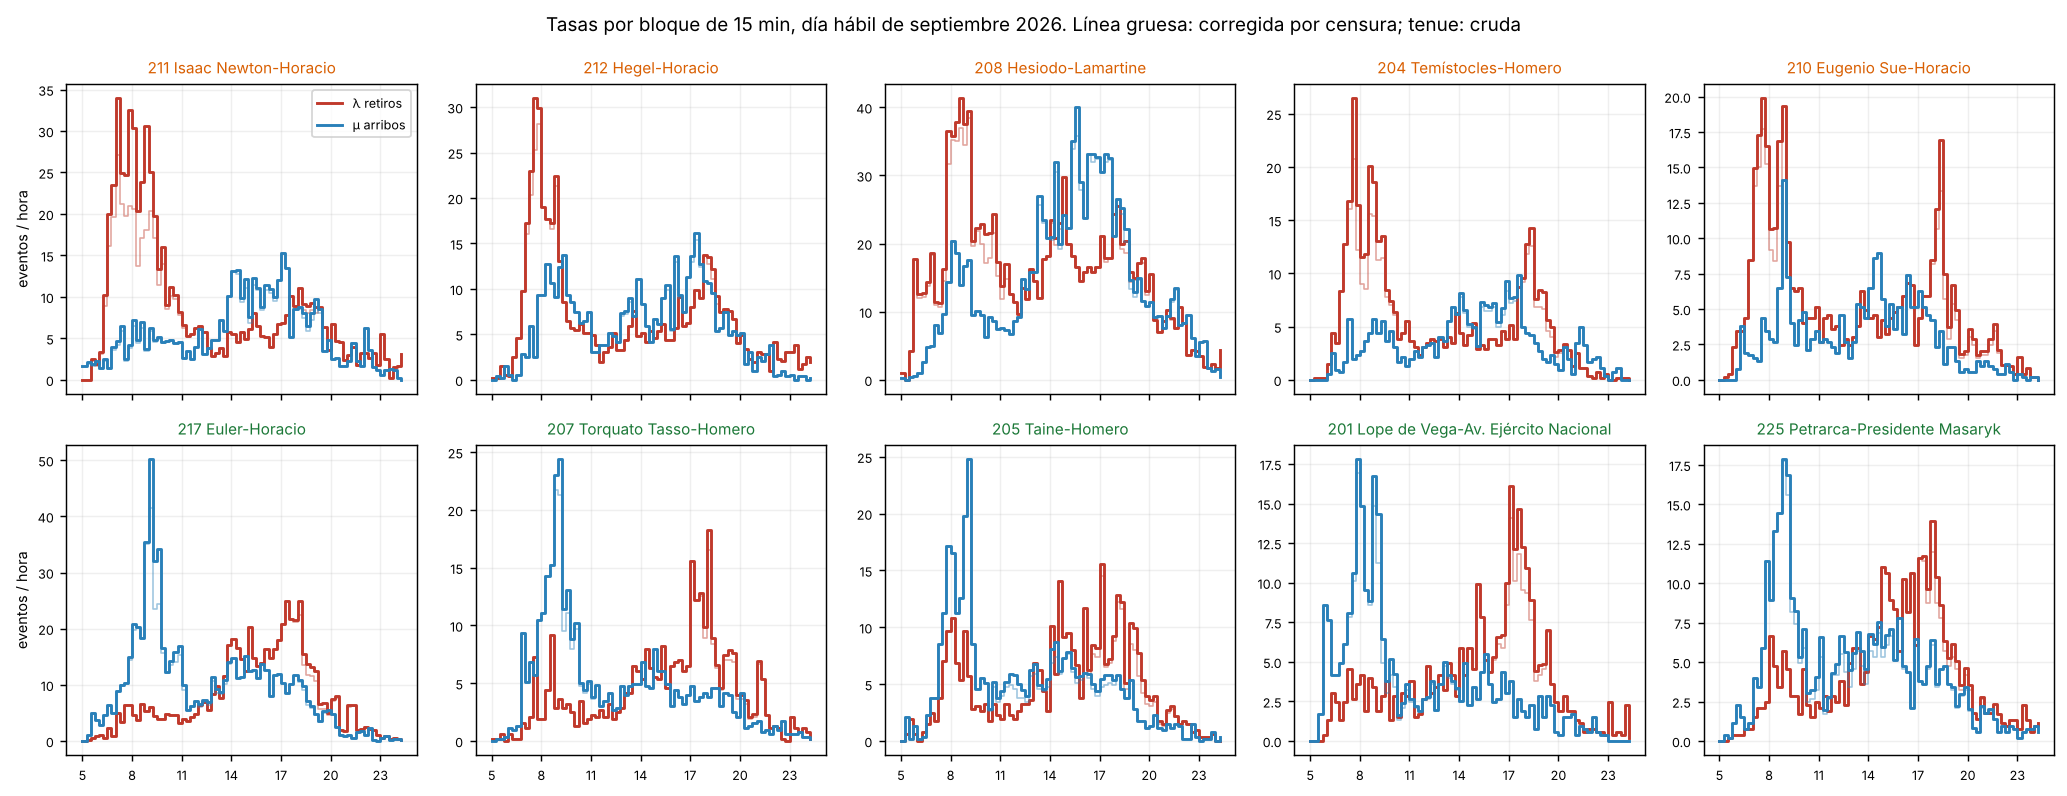

In [22]:
# 1. tasas crudas vs corregidas
fig, axs = plt.subplots(2, 5, figsize=(16, 6.2), dpi=130, sharex=True)
for ax, s in zip(axs.flat, SUBRED):
    ax.step(xh, cruda[(s, "ret")] * 60, where="post", color="#c0392b", lw=.9, alpha=.45)
    ax.step(xh, corr[(s, "ret")] * 60, where="post", color="#c0392b", lw=1.6, label="λ retiros")
    ax.step(xh, cruda[(s, "arr")] * 60, where="post", color="#2980b9", lw=.9, alpha=.45)
    ax.step(xh, corr[(s, "arr")] * 60, where="post", color="#2980b9", lw=1.6, label="μ arribos")
    ax.set_title(f"{s} {NOM[s]}", fontsize=8.5, color=rol[s]); ax.set_xticks(ticks); ax.tick_params(labelsize=7); ax.grid(alpha=.2)
axs[0, 0].legend(fontsize=7); axs[0, 0].set_ylabel("eventos / hora", fontsize=8); axs[1, 0].set_ylabel("eventos / hora", fontsize=8)
fig.suptitle("Tasas por bloque de 15 min, día hábil de septiembre 2026. Línea gruesa: corregida por censura; tenue: cruda", fontsize=10.5)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_tasas.png"); plt.show()

### Prueba de exponencialidad (QQ contra Exp(1))
Si el modelo fuera perfecto, las curvas quedarían sobre la línea roja. La cola que se levanta en los retiros de las fuentes son los huecos de estación vacía.

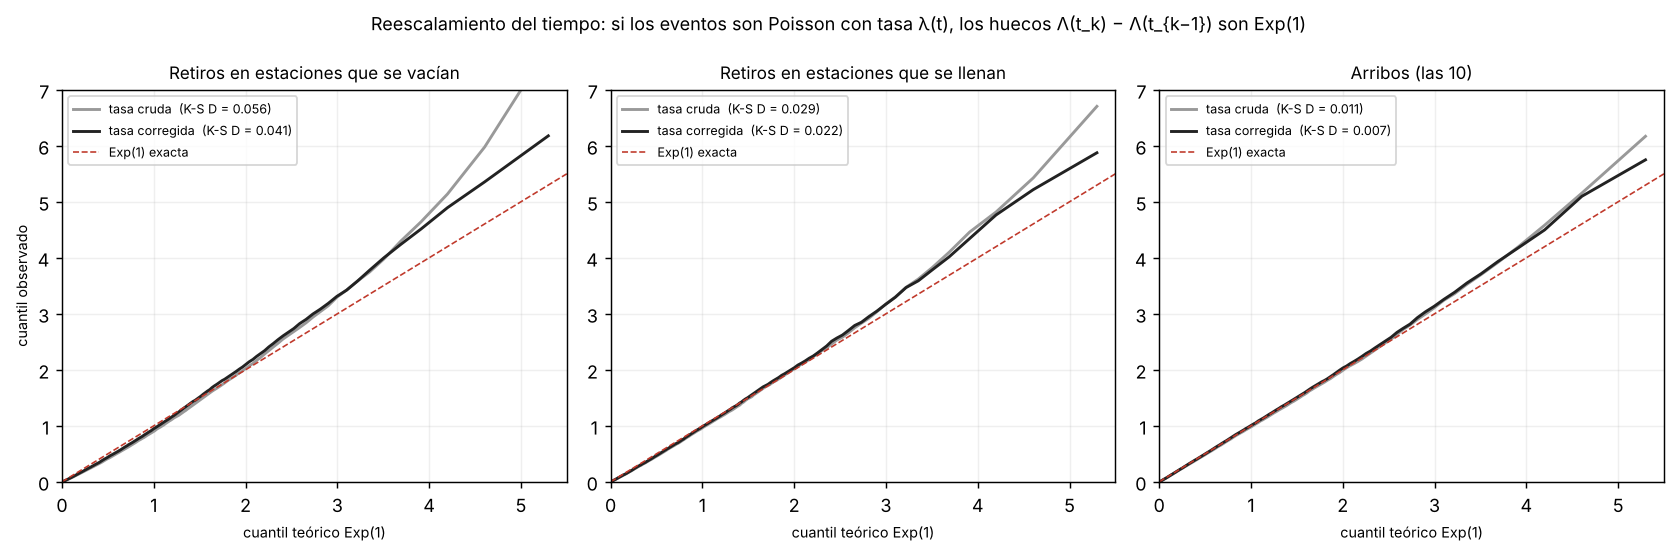

In [23]:
# 2. QQ de los huecos reescalados contra Exp(1)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), dpi=130)
qs = np.linspace(.005, .995, 199); teo = -np.log(1 - qs)
for ax, (tit, grupo, tp) in zip(axs, [("Retiros en estaciones que se vacían", FUENTES, "ret"),
                                     ("Retiros en estaciones que se llenan", SUMIDEROS, "ret"),
                                     ("Arribos (las 10)", SUBRED, "arr")]):
    for lab, cc in (("cruda", "#999999"), ("corregida", "#222222")):
        z = np.concatenate([Z[(s, tp, lab)] for s in grupo])
        D = stats.kstest(z, "expon").statistic
        ax.plot(teo, np.quantile(z, qs), color=cc, lw=1.6, label=f"tasa {lab}  (K-S D = {D:.3f})")
    ax.plot([0, 5.5], [0, 5.5], ls="--", color="#c0392b", lw=.9, label="Exp(1) exacta")
    ax.set_title(tit, fontsize=9.5); ax.set_xlabel("cuantil teórico Exp(1)", fontsize=8); ax.set_xlim(0, 5.5); ax.set_ylim(0, 7)
    ax.legend(fontsize=7, loc="upper left"); ax.grid(alpha=.2)
axs[0].set_ylabel("cuantil observado", fontsize=8)
fig.suptitle("Reescalamiento del tiempo: si los eventos son Poisson con tasa λ(t), los huecos Λ(t_k) − Λ(t_{k−1}) son Exp(1)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_qq_exponencial.png"); plt.show()

### Cuándo está censurada la demanda

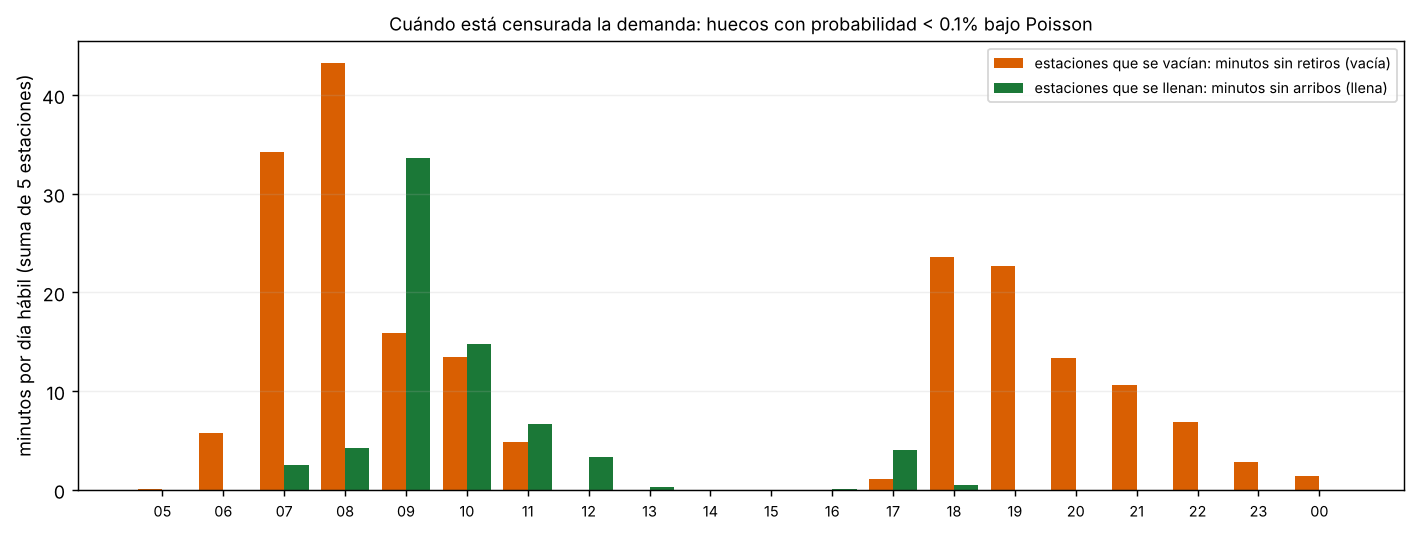

In [24]:
# 3. censura por hora del día
fig, ax = plt.subplots(figsize=(11, 4.2), dpi=130)
hh = np.arange(5, 25)
def min_por_hora(e):
    v = np.zeros(len(hh))
    for a, b in zip(e.inicio_min, e.fin_min):
        for m in np.arange(np.floor(a), b):
            i = int(m // 60) - 5
            if 0 <= i < len(hh): v[i] += 1
    return v / ND
v1 = min_por_hora(EP[EP.codigo.isin(FUENTES) & EP.tipo.str.startswith("vacía")])
v2 = min_por_hora(EP[EP.codigo.isin(SUMIDEROS) & EP.tipo.str.startswith("llena")])
ax.bar(hh - .2, v1, width=.4, color=col_f, label="estaciones que se vacían: minutos sin retiros (vacía)")
ax.bar(hh + .2, v2, width=.4, color=col_s, label="estaciones que se llenan: minutos sin arribos (llena)")
ax.set_xticks(hh); ax.set_xticklabels([f"{h % 24:02d}" for h in hh], fontsize=8)
ax.set_ylabel("minutos por día hábil (suma de 5 estaciones)"); ax.legend(fontsize=8); ax.grid(alpha=.2, axis="y")
ax.set_title("Cuándo está censurada la demanda: huecos con probabilidad < 0.1% bajo Poisson", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_censura_por_hora.png"); plt.show()

### Probabilidad de estación vacía / llena durante el día
Partiendo del mejor inventario posible a las 05:00 y **sin redistribuir**.

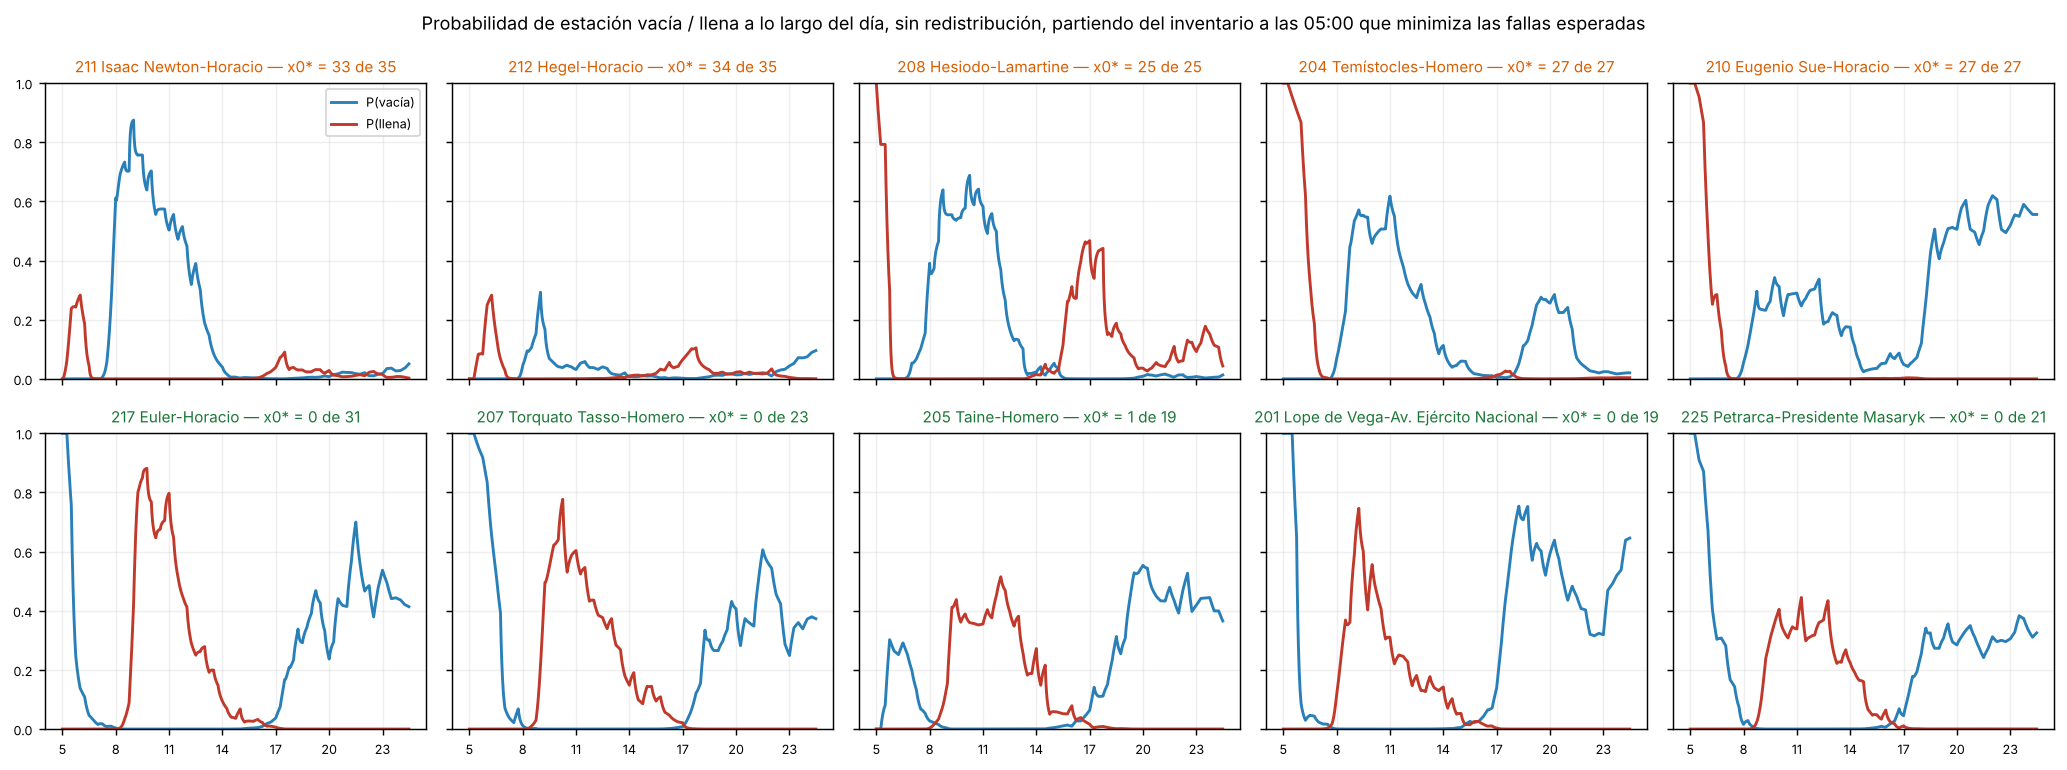

In [25]:
# 4. P(vacía), P(llena) con el mejor inventario inicial
fig, axs = plt.subplots(2, 5, figsize=(16, 6), dpi=130, sharex=True, sharey=True)
xm = MIN / 60
for ax, s in zip(axs.flat, SUBRED):
    cv = curvas[s]; x = cv["x_opt"]
    ax.plot(xm, cv["p0"][x], color="#2980b9", lw=1.6, label="P(vacía)")
    ax.plot(xm, cv["pK"][x], color="#c0392b", lw=1.6, label="P(llena)")
    ax.set_title(f"{s} {NOM[s]} — x0* = {x} de {K[s]}", fontsize=8.5, color=rol[s])
    ax.set_xticks(ticks); ax.tick_params(labelsize=7); ax.grid(alpha=.2); ax.set_ylim(0, 1)
axs[0, 0].legend(fontsize=7)
fig.suptitle("Probabilidad de estación vacía / llena a lo largo del día, sin redistribución, partiendo del inventario a las 05:00 que minimiza las fallas esperadas", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_prob_falla.png"); plt.show()

### Fallas esperadas según el inventario inicial
La línea punteada es el mínimo. Aun en el mínimo las fallas son altas: un inventario inicial no alcanza, hay que mover bicis durante el día (Etapa 3).

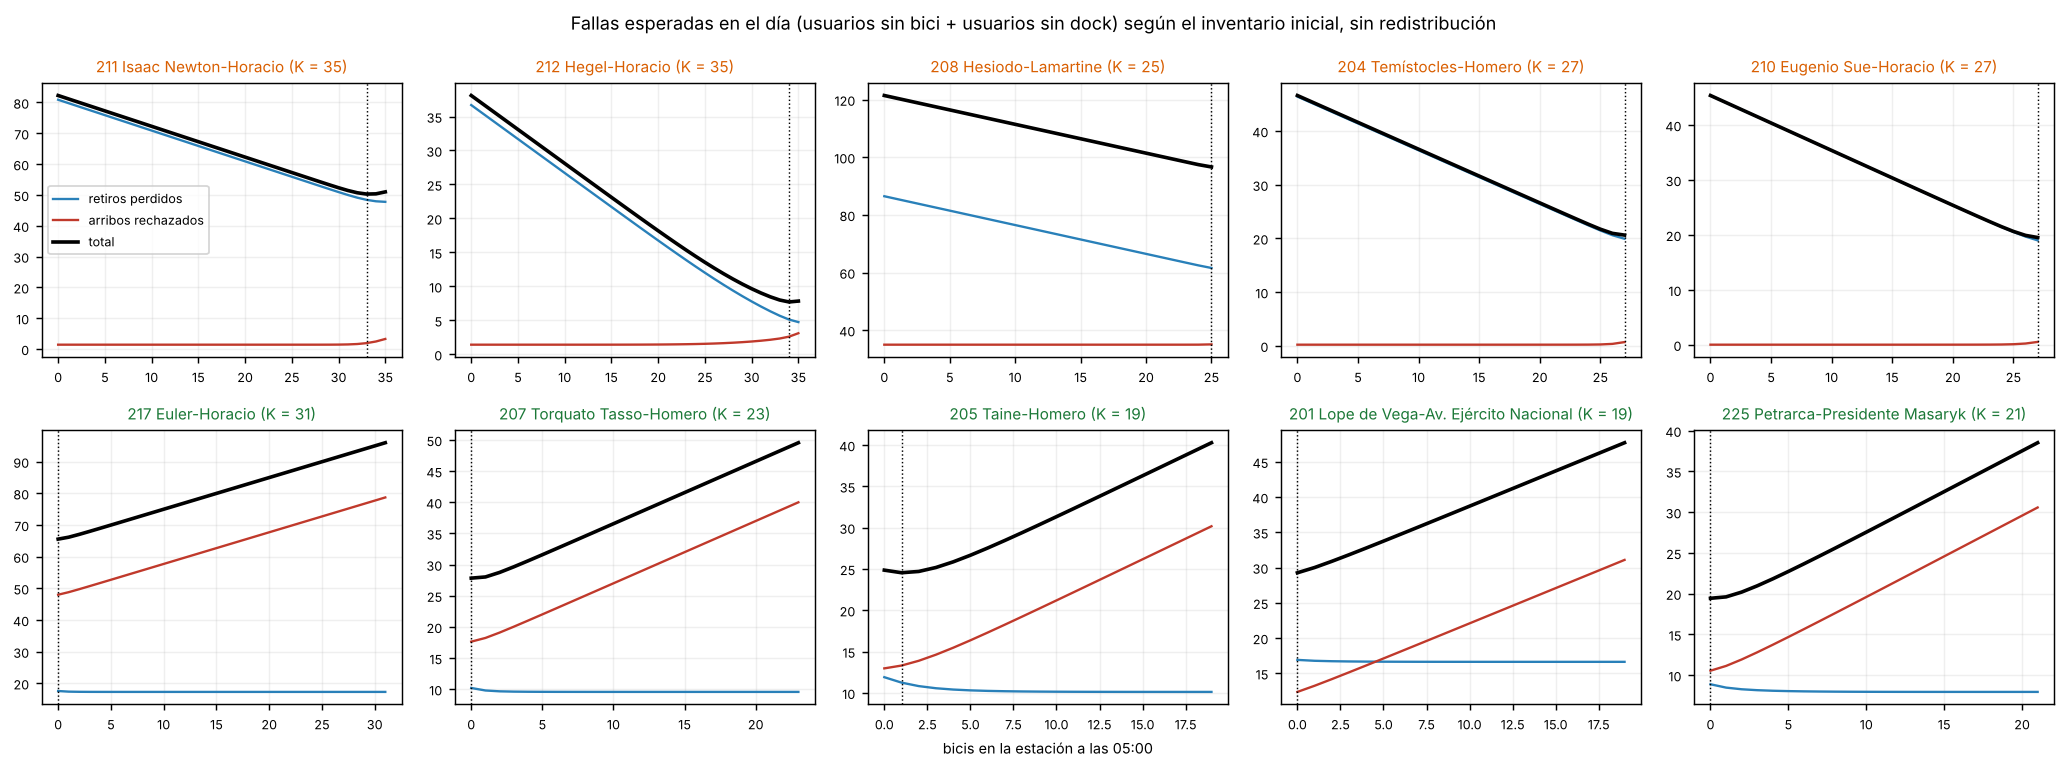

In [26]:
# 5. fallas esperadas vs inventario inicial
fig, axs = plt.subplots(2, 5, figsize=(16, 6), dpi=130)
for ax, s in zip(axs.flat, SUBRED):
    d = X0[X0.codigo == s]
    ax.plot(d.x0_05h, d.E_retiros_perdidos, color="#2980b9", lw=1.3, label="retiros perdidos")
    ax.plot(d.x0_05h, d.E_arribos_rechazados, color="#c0392b", lw=1.3, label="arribos rechazados")
    ax.plot(d.x0_05h, d.E_fallas, color="k", lw=2, label="total")
    ax.axvline(curvas[s]["x_opt"], color="k", ls=":", lw=.8)
    ax.set_title(f"{s} {NOM[s]} (K = {K[s]})", fontsize=8.5, color=rol[s]); ax.tick_params(labelsize=7); ax.grid(alpha=.2)
axs[0, 0].legend(fontsize=7); axs[1, 2].set_xlabel("bicis en la estación a las 05:00", fontsize=8)
fig.suptitle("Fallas esperadas en el día (usuarios sin bici + usuarios sin dock) según el inventario inicial, sin redistribución", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_fallas_vs_inventario.png"); plt.show()

## 11. Conclusiones de la Etapa 2

- Arribos: Poisson y exponencial se aceptan. Retiros: se acercan, la desviación viene de la censura.
- Bloques de 15 min (la tasa cambia dentro de la hora). El día de la semana no importa.
- Censura detectada justo donde se esperaba (fuentes vacías 7–9 h y 18–20 h, sumideros llenos 9–11 h), verificada con el ID de la bici. La demanda corregida es una cota inferior.
- El operador hoy mete en neto ~124 bicis/día a las fuentes, sobre todo entre 8 y 9 h.
- Sin redistribución, aun con el mejor inventario inicial, hay ~360 fallas esperadas al día en la subred.
- 211 y 212 funcionan como una sola estación; como nodo de 70 docks las fallas de esa esquina bajan a la mitad.

**Límites:** la demanda corregida es un mínimo; el usuario rechazado aparece en la estación vecina; las estaciones no están acopladas en el modelo; no se ve la demanda de quien ya no va porque "siempre está vacía"; un solo mes (lluvias).